# Wannier 90 Tight binding handler

- Read tight binding data from W90
- Plot heat map

## Imports

In [1]:
%pylab inline
import sys, os
import matplotlib.pylab as pylab
pylab.rcParams['figure.figsize'] = 8, 6  # that's default image size for this interactive session
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))
from ipywidgets.widgets import interactive, fixed, interact
%config InlineBackend.figure_format = 'retina'


import matplotlib.pyplot as plt
import numpy as np

import pandas as pd 


Populating the interactive namespace from numpy and matplotlib


In [2]:
from jhr.plotters._base import annotate
from jhr.codes import W90
from jhr.plotters.plots import tbHeat
from jhr.codes.W90 import GetOneCell, GetHomePlusNeighbors, GetAllContributions

## Tight binding Hamiltonian (Wannier90)

(104976, 7)
(104976, 7)


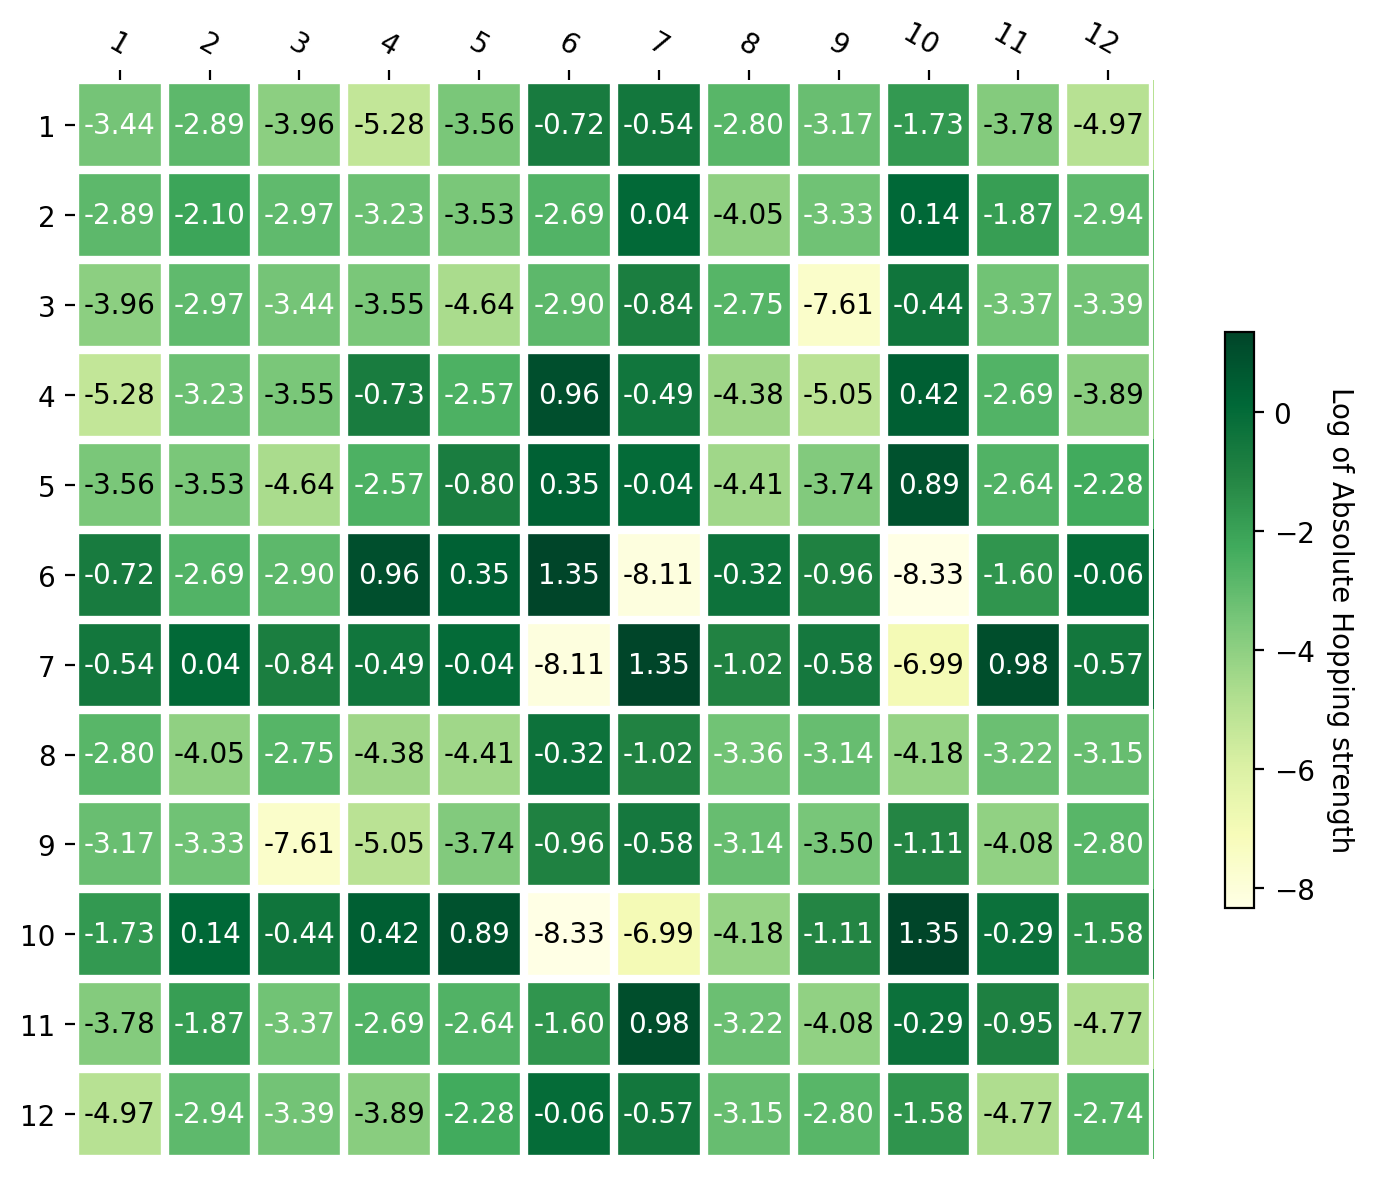

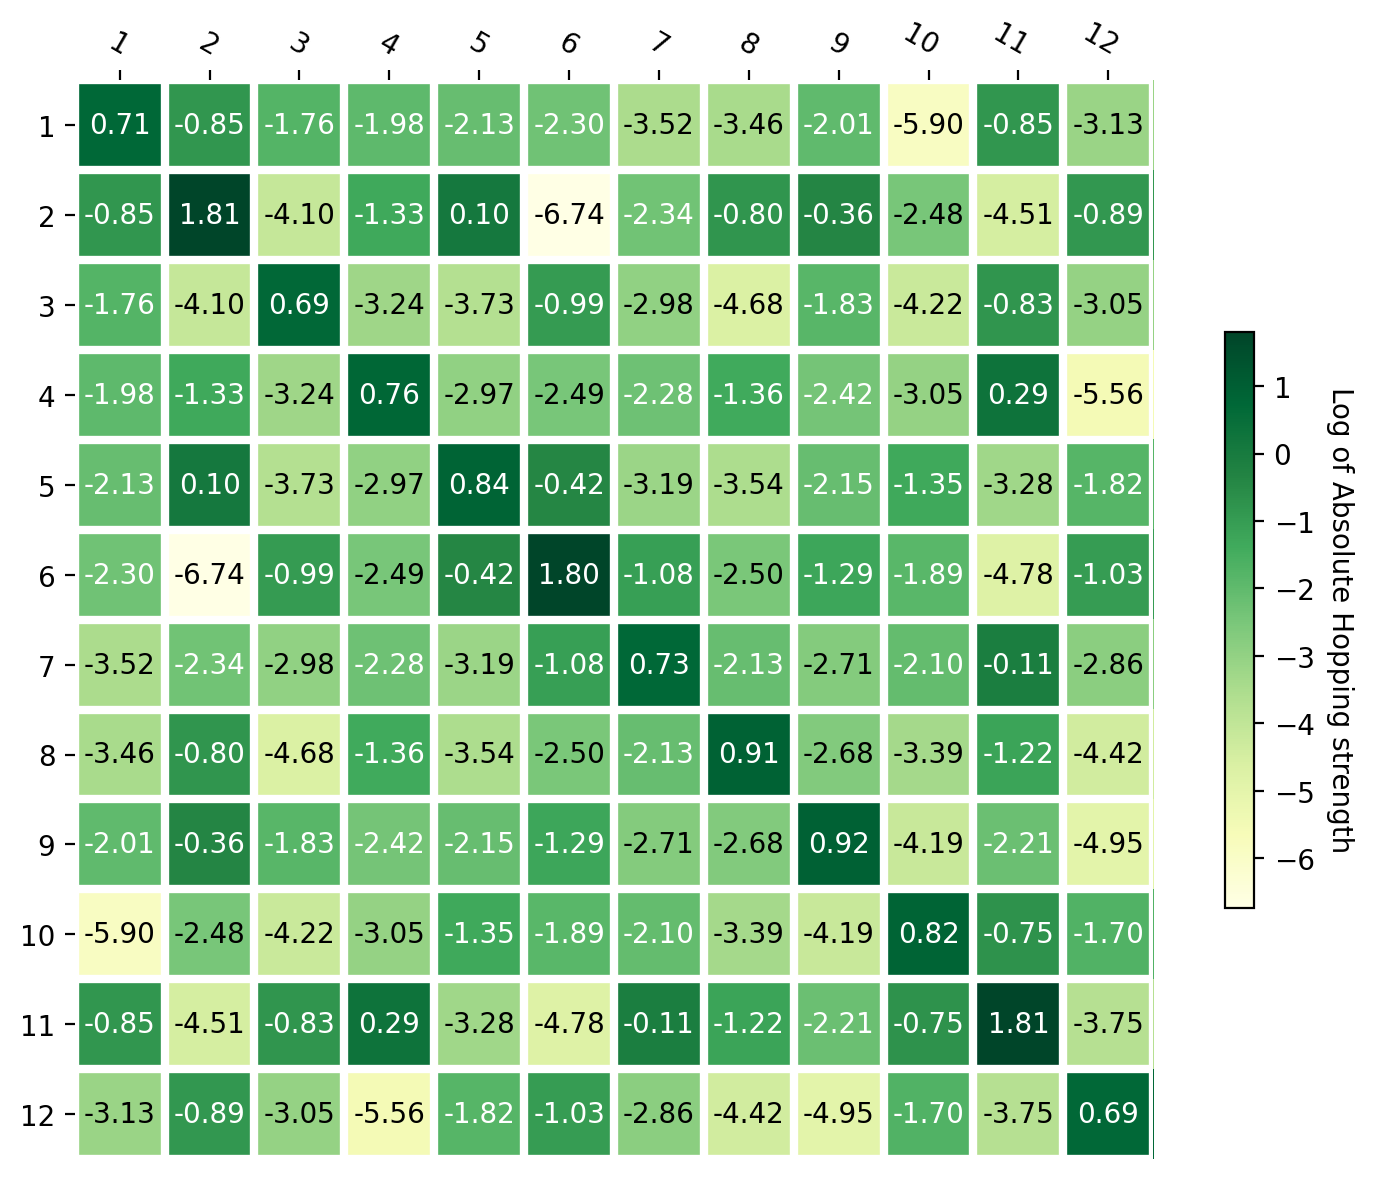

In [3]:
files = ["CsPBBr3_hr.dat", "CsPBI3_hr.dat"]

H_all = []

for f in files:


  hr = genfromtxt(f, skip_header=52)
  num_basis = 12

  print(hr.shape)

  # Print the eigenvalues for just the consideration of one unit cell.
  H = GetOneCell(hr, 0,0,0, num_basis = num_basis)
  
  # print(eig(H)[0])

  H = GetHomePlusNeighbors(hr, num_basis = num_basis)
  # print(eig(H)[0])

  # H = GetAllContributions(hr, num_basis = num_basis)
  # print(eig(H)[0])

  H_all.append(H)


#______PLOT_____


for H in H_all:
  fig, ax = plt.subplots()
  tbHeat(np.log(np.abs(H)), num_basis = num_basis, cbar_kw = {'fraction': 0.02})
  fig.tight_layout()
  plt.show()

## Heat Map

In [12]:
WannSpreads

[2.70095256,
 9.87519872,
 2.49366726,
 3.18367046,
 3.95205533,
 9.77933602,
 2.86826488,
 4.61549418,
 4.71768961,
 3.80369405,
 9.89722555,
 2.49632316]

In [7]:
#Wannier spreads
file_path = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/Abinitio-Codes/data/wann_tb_files/CsPbI3_wan/CsPBI3.wout' 


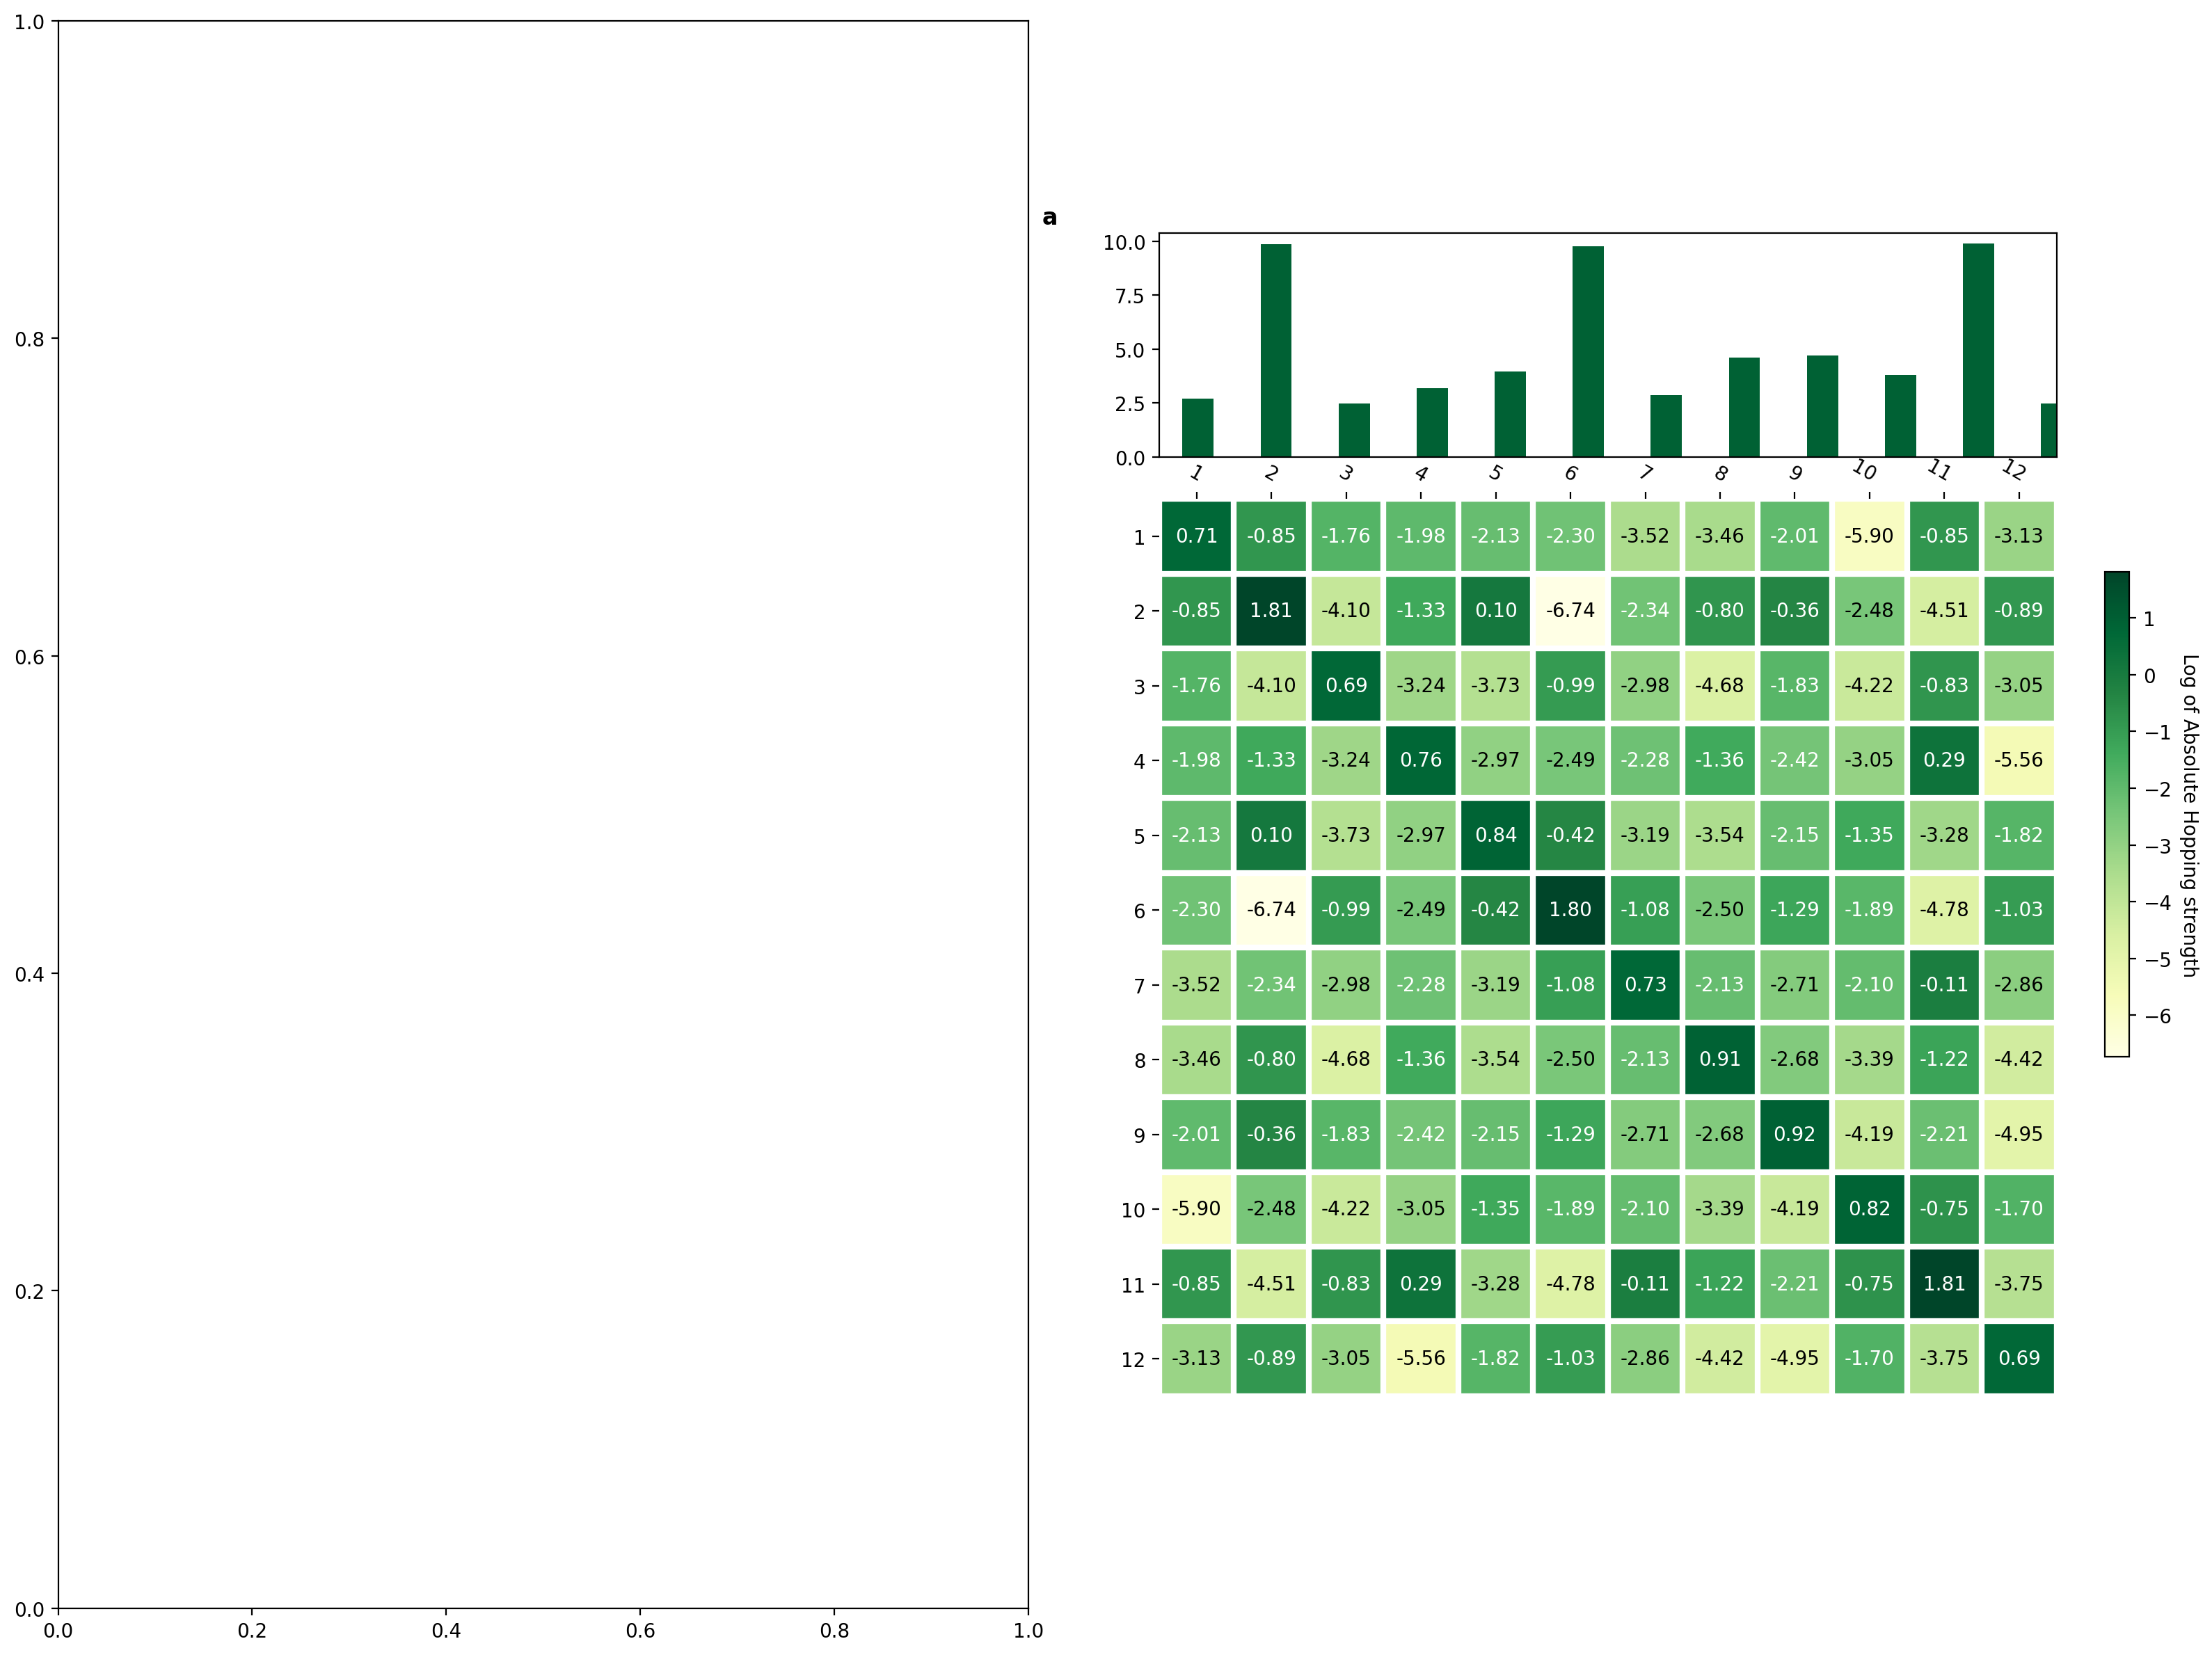

In [11]:
#__________Read Wannier spreads___________

# file_path = '/home/fes33/Documents/GIK - R&D/Personal - Papers and Reports/--Libraries/abinit/Abinitio-Codes/data/wann_tb_files/CsPbBr3_wan/CsPBBr3.wout'  # Replace with your actual file path
# WannSpreads = W90.readSpread(file_path)



fig, ((ax, ax2)) = plt.subplots(1, 2, figsize=(16, 12))

#__________________

# [axdiv1, axdiv2] = ax_divider(ax, divisions = 2, size =(0.25, 0.1), direction = "top", pad = 0.3)

# tbHeat(np.log(np.abs(H_all[0])), num_basis = num_basis, ax = axdiv1, cbar_kw = {'fraction': 0.025})
# WannSpreads = W90.readSpread(file_path)
# lab = list(range(1,13))

# plt.sca(axdiv2)
# axdiv2.set_xlim(0.5, len(lab))
# axdiv2.set_xticks([])
# plt.bar(lab, WannSpreads, color = '#006134', align='center', width=0.4)

#_______________________________

[axdiv1, axdiv2] = ax_divider(ax2, divisions = 2, size =(0.25, 0.1), direction = "top", pad = 0.3)

tbHeat(np.log(np.abs(H_all[1])), num_basis = num_basis, ax = axdiv1, cbar_kw = {'fraction': 0.025})
WannSpreads = W90.readSpread(file_path)
lab = list(range(1,13))

plt.sca(axdiv2)
axdiv2.set_xlim(0.5, len(lab))
axdiv2.set_xticks([])
plt.bar(lab, WannSpreads, color = '#006134', align='center', width=0.4)

#==================================

annotate(labels = ['', '', 'a', '', 'b', ''])

plt.tight_layout()
plt.show()


In [10]:
def ax_divider(ax, divisions = 4, size =(1.5, 1), direction = "bottom", pad = 0):
  """
  Divides vertically if no zip.
  Usage:
      axs = pm.ax_divider(ax0, divisions = 5)


  Args:
      direction: direction in which to add axes: "top", "bottom", "right", "left"
  Returns:
      Axes
  """
  from mpl_toolkits.axes_grid1 import make_axes_locatable
  from mpl_toolkits.axes_grid1 import Divider
  divider = make_axes_locatable(ax)

  axes = [ax]
  for i in range(divisions-1):
      ax2 = divider.append_axes(direction, size="25%", pad=pad)
      
      axes.append(ax2)

  return axes 


In [ ]:
df = pd.DataFrame(np.round(np.log(np.abs(H)), 8))

df2 = df
rng = -1
# df2[(df2 < rng) & (df2 > -rng)] = 0
df2[(df2 < rng)] = 0
display(df2.style.background_gradient(cmap='viridis'))

,0,1,2,3,4,5,6,7,8,9,10,11
0,0.685174,-0.424061,0.000000,0.000000,0.000000,-0.975189,0.000000,0.000000,0.000000,0.000000,-0.313544,0.000000
1,-0.424061,1.707858,0.000000,-0.878858,0.604701,-0.917847,-0.165764,-0.155349,-0.668616,0.682725,0.000000,-0.297079
2,0.000000,0.000000,0.709955,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.383214,0.000000
3,0.000000,-0.878858,0.000000,0.690994,0.000000,0.231968,0.000000,0.000000,0.000000,0.000000,0.092167,0.000000
4,0.000000,0.604701,0.000000,0.000000,0.627826,0.068388,0.000000,0.000000,0.000000,0.000000,-0.590583,0.000000
5,-0.975189,-0.917847,0.000000,0.231968,0.068388,1.719776,-0.453618,0.984758,-0.646103,0.000000,0.000000,0.000000
6,0.000000,-0.165764,0.000000,0.000000,0.000000,-0.453618,0.690874,0.000000,0.000000,0.000000,-0.208943,0.000000
7,0.000000,-0.155349,0.000000,0.000000,0.000000,0.984758,0.000000,0.662693,0.000000,0.000000,0.000000,0.000000
8,0.000000,-0.668616,0.000000,0.000000,0.000000,-0.646103,0.000000,0.000000,0.674594,0.000000,1.028985,0.000000
9,0.000000,0.682725,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.653636,-0.047529,0.000000
